In [1]:
import lsdb

from hats.catalog import ExtensionProperties
from upath import UPath

lsdb.show_versions()


--------      SYSTEM INFO      --------
python        : 3.13.16
python-bits   : 64
OS            : Linux
OS-release    : 5.14.0-570.60.1+28.1.el9_6_ciq.x86_64
Version       : #1 SMP PREEMPT_DYNAMIC Thu Nov 12 23:52:02 UTC 2026
machine       : x86_64
processor     : x86_64
byteorder     : little
LC_ALL        : 
LANG          : C.UTF-8
--------   INSTALLED VERSIONS   --------
lsdb          : 0.11.2
hats          : 0.11.2
nested-pandas : 0.7.3
pandas        : 3.0.6
numpy         : 2.3.5
dask          : 2026.6.0
pyarrow       : 26.0.1
fsspec        : 2026.6.0


# Milestone 5: Federated Data Access (Month 6; objective 1b)

Definition: A collection-dataset mechanism supports transparent aggregation across remote stores.

Quantitative Metrics: User can query the main catalog from one location and receive (e.g., images and spectra) extensions from another.

In [2]:
# TODO: Make sure the base catalog only has non-extension cols.
columns = ["object_id_mmu_legacysurvey_dr10_south_21", "ra_mmu_legacysurvey_dr10_south_21",	"dec_mmu_legacysurvey_dr10_south_21"]
collection_path = UPath("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2_small")
milestone2 = lsdb.open_catalog(collection_path, columns=columns)
milestone2

,object_id_mmu_legacysurvey_dr10_south_21,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21
npartitions=10,,,
"Order: 7, Pixel: 41472",string[pyarrow],double[pyarrow],double[pyarrow]
...,...,...,...
"Order: 7, Pixel: 41508",...,...,...
"Order: 7, Pixel: 41509",...,...,...


View the loaded and available extensions:

In [3]:
print(f"Loaded extensions: {milestone2.extensions}")
print(f"Available extensions: {milestone2.all_extensions}")

Loaded extensions: ()
Available extensions: {'cutouts': 'milestone2_cutouts.properties', 'spectra': 'milestone2_spectra.properties'}


The extensions are defined locally, in their respective properties files. The data is located remotely.

In [4]:
ExtensionProperties.read_from_file(collection_path / "milestone2_cutouts.properties")

name                       milestone2_cutouts
catalog_type               extension
primary_catalog            milestone2_small_with_cutouts
primary_column             object_id_mmu_legacysurvey_dr10_south_21
join_catalog               hf://datasets/LSDB/milestone2_cutouts
join_column                object_id_mmu_legacysurvey_dr10_south_21
extension_columns          image_flux_g image_mask_g image_ivar_g image_flux_r image_mask_r image_ivar_r
extension_join_style       left
shares_primary_coordinates True
extension_product_type     image

In [5]:
ExtensionProperties.read_from_file(collection_path / "milestone2_spectra.properties")

name                       milestone2_spectra
catalog_type               extension
primary_catalog            milestone2_small_with_spectra
primary_column             object_id_mmu_legacysurvey_dr10_south_21
join_catalog               https://data.lsdb.io/unstable/milestone2_spectra
join_column                object_id_mmu_legacysurvey_dr10_south_21
extension_columns          spectrum
extension_join_style       left
shares_primary_coordinates True
extension_product_type     spectra

Load the cutouts from HuggingFace:

/sdf/home/s/stavar/.local/lib/python3.13/site-packages/lsdb/operations/functions/join_catalog_data.py:433: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(
Building task graph...


Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

,object_id_mmu_legacysurvey_dr10_south_21,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,image_flux_g,image_mask_g,image_ivar_g,image_flux_r,image_mask_r,image_ivar_r
729594401347125473,1966p250-1555,196.606908,24.939503,0.0145-0.00643,10,1.5e+057.83e+04,0.0317-0.0129,10,4.13e+041.97e+04
729594698490995941,1966p250-1020,196.570395,24.925320,0.00912-0.0072,10,8.87e+043.6e+04,0.0195-0.0144,10,2.17e+048.25e+03
729594759487585526,1966p250-1428,196.598615,24.943988,0.0104-0.00718,21,1.08e+053.91e+04,0.0214-0.0142,21,2.19e+041.21e+04
729594842788931257,1966p250-800,196.556864,24.950420,0.0258-0.00706,21,1.13e+052.48e+04,0.0345-0.0147,21,2.71e+045.42e+03
729594847830835346,1966p250-692,196.551128,24.949316,0.0258-0.00683,21,1.14e+052.49e+04,0.0351-0.0143,21,2.71e+045.42e+03

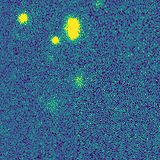
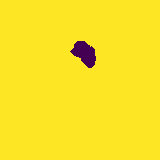
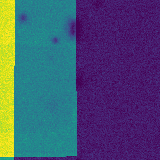
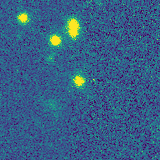
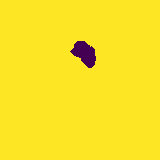
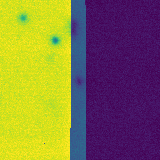
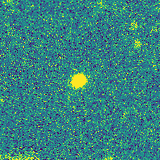
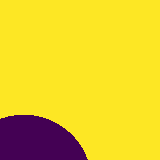
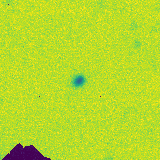
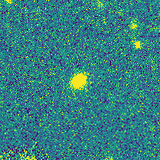
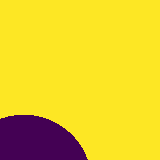
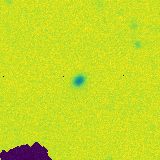
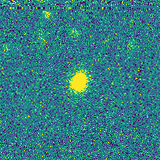
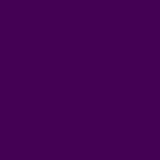
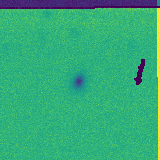
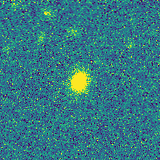
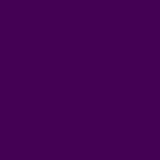
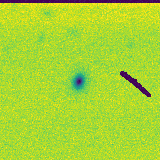
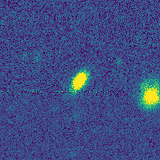
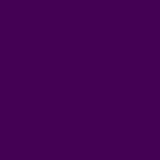
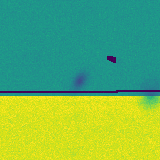
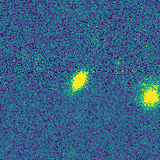
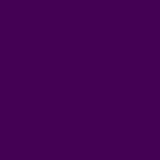
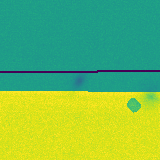
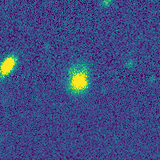
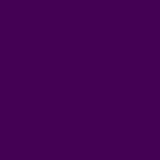
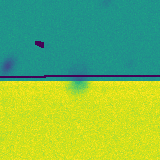
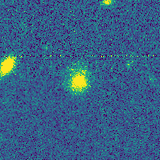
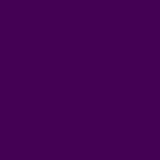
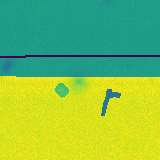

In [6]:
# TODO: Check that for the full version of the catalog the margin is not empty
milestone2 = milestone2.load_extension("cutouts")
milestone2.head()

Load the spectra, from UW, on top of the existing Catalog:

/sdf/home/s/stavar/.local/lib/python3.13/site-packages/lsdb/operations/functions/join_catalog_data.py:433: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(
Building task graph...


Computing Catalog:   0%|          | 0/11 [00:00<?, ?it/s]

object_id_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                                   
729594401347125473                            1966p250-1555   
729594698490995941                            1966p250-1020   
729594759487585526                            1966p250-1428   
729594842788931257                             1966p250-800   
729594847830835346                             1966p250-692   

                    ra_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                             
729594401347125473                         196.606908   
729594698490995941                         196.570395   
729594759487585526                         196.598615   
729594842788931257                         196.556864   
729594847830835346                         196.551128   

                    dec_mmu_legacysurvey_dr10_south_21       image_flux_g  \
_healpix_29                                                                 
729594401347125473                           24.939503  [160×160] float32   
729594698490995941                            24.92532  [160×160] float32   
729594759487585526                           24.943988  [160×160] float32   
729594842788931257                            24.95042  [160×160] float32   
729594847830835346                           24.949316  [160×160] float32   

                      image_mask_g       image_ivar_g       image_flux_r  \
_healpix_29                                                                
729594401347125473  [160×160] bool  [160×160] float32  [160×160] float32   
729594698490995941  [160×160] bool  [160×160] float32  [160×160] float32   
729594759487585526  [160×160] bool  [160×160] float32  [160×160] float32   
729594842788931257  [160×160] bool  [160×160] float32  [160×160] float32   
729594847830835346  [160×160] bool  [160×160] float32  [160×160] float32   

                      image_mask_r       image_ivar_r  \
_healpix_29                                             
729594401347125473  [160×160] bool  [160×160] float32   
729594698490995941  [160×160] bool  [160×160] float32   
729594759487585526  [160×160] bool  [160×160] float32   
729594842788931257  [160×160] bool  [160×160] float32   
729594847830835346  [160×160] bool  [160×160] float32   

                                                             spectrum  
_healpix_29                                                            
729594401347125473  [{flux: 5.987331, ivar: 0.153955, lsf_sigma: 0...  
729594698490995941  [{flux: -1.951323, ivar: 0.044572, lsf_sigma: ...  
729594759487585526  [{flux: 3.759151, ivar: 0.04319, lsf_sigma: 0....  
729594842788931257  [{flux: -0.543011, ivar: 0.046027, lsf_sigma: ...  
729594847830835346  [{flux: 18.797222, ivar: 0.016184, lsf_sigma: ...
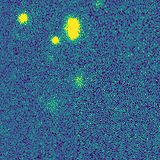
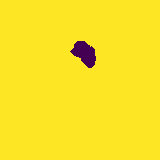
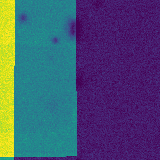
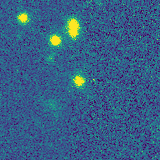
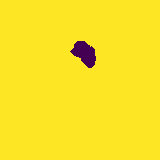
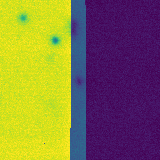
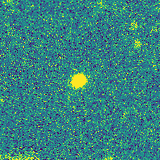
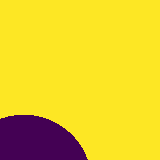
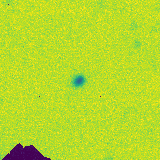
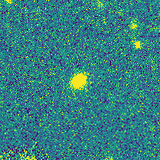
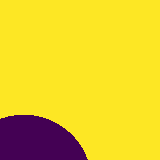
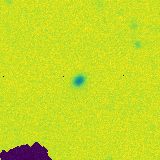
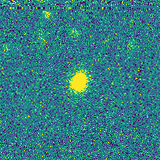
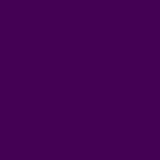
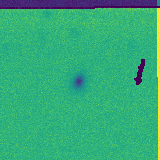
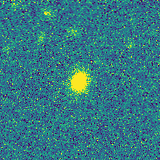
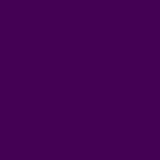
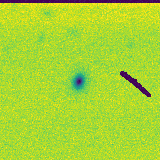
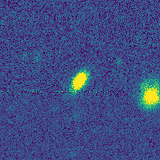
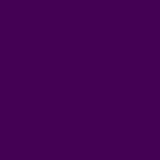
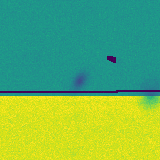
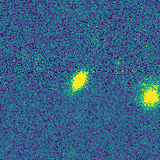
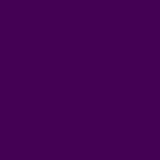
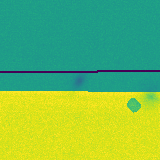
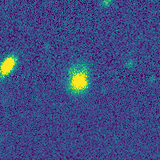
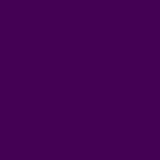
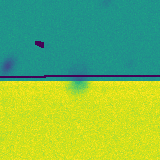
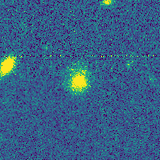
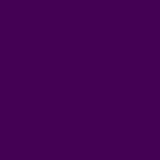
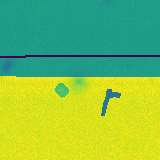

In [7]:
milestone2 = milestone2.load_extension("spectra")
milestone2.head()

In [8]:
print(f"Loaded extensions: {milestone2.extensions}")

Loaded extensions: ('cutouts', 'spectra')
